In [1]:
pip install pandas pyarrow matplotlib seaborn

In [2]:
from google.colab import files

uploaded = files.upload()

KeyboardInterrupt: 

In [3]:
from google.colab import files

uploaded = files.upload()

Saving yellow_tripdata_2026-01.parquet to yellow_tripdata_2026-01.parquet


In [4]:
import pandas as pd
import numpy as np

file_name = next(iter(uploaded))

df = pd.read_parquet(file_name)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst 5 rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)

Dataset shape: (3724889, 20)

Column names:
['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee', 'cbd_congestion_fee']

First 5 rows:


,VendorID,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,RatecodeID,store_and_fwd_flag,PULocationID,DOLocationID,payment_type,fare_amount,extra,mta_tax,tip_amount,tolls_amount,improvement_surcharge,total_amount,congestion_surcharge,Airport_fee,cbd_congestion_fee
0,2,2026-01-01 00:54:04,2026-01-01 00:59:37,1.0,0.97,1.0,N,239,238,1,7.2,1.00,0.5,3.66,0.0,1.0,15.86,2.5,0.0,0.00
1,1,2026-01-01 00:34:04,2026-01-01 00:39:47,0.0,0.90,1.0,N,163,162,2,7.9,4.25,0.5,0.00,0.0,1.0,13.65,2.5,0.0,0.75
2,1,2026-01-01 00:57:06,2026-01-01 01:05:59,0.0,1.40,1.0,N,43,237,1,10.7,4.25,0.5,2.50,0.0,1.0,18.95,2.5,0.0,0.75
3,2,2026-01-01 00:15:22,2026-01-01 00:58:10,4.0,5.58,1.0,N,142,209,1,38.7,1.00,0.5,11.11,0.0,1.0,55.56,2.5,0.0,0.75
4,2,2026-01-01 00:27:13,2026-01-01 00:40:43,0.0,2.16,1.0,N,88,144,1,13.5,1.00,0.5,3.85,0.0,1.0,23.10,2.5,0.0,0.75



Data types:
VendorID                          int32
tpep_pickup_datetime     datetime64[us]
tpep_dropoff_datetime    datetime64[us]
passenger_count                 float64
trip_distance                   float64
RatecodeID                      float64
store_and_fwd_flag               object
PULocationID                      int32
DOLocationID                      int32
payment_type                      int64
fare_amount                     float64
extra                           float64
mta_tax                         float64
tip_amount                      float64
tolls_amount                    float64
improvement_surcharge           float64
total_amount                    float64
congestion_surcharge            float64
Airport_fee                     float64
cbd_congestion_fee              float64
dtype: object


In [5]:
print("Total records:", len(df))
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isnull().sum().sort_values(ascending=False).head(15))

print("\nStatistical summary:")
display(df.describe().T)

Total records: 3724889
Duplicate rows: 0

Missing values:
passenger_count          1088058
congestion_surcharge     1088058
store_and_fwd_flag       1088058
RatecodeID               1088058
Airport_fee              1088058
tpep_dropoff_datetime          0
VendorID                       0
tpep_pickup_datetime           0
DOLocationID                   0
payment_type                   0
trip_distance                  0
PULocationID                   0
extra                          0
fare_amount                    0
mta_tax                        0
dtype: int64

Statistical summary:


,count,mean,min,25%,50%,75%,max,std
VendorID,3724889.0,1.873598,1.0,2.0,2.0,2.0,7.0,0.701458
tpep_pickup_datetime,3724889,2026-01-17 01:44:52.106518,2025-12-31 23:57:29,2026-01-09 17:51:59,2026-01-16 21:20:56,2026-01-24 07:25:11,2026-02-01 00:45:01,NaN
tpep_dropoff_datetime,3724889,2026-01-17 02:02:03.696138,2025-12-31 23:57:32,2026-01-09 18:08:47,2026-01-16 21:36:14,2026-01-24 07:40:22,2026-02-01 23:35:31,NaN
passenger_count,2636831.0,1.256271,0.0,1.0,1.0,1.0,9.0,0.670243
trip_distance,3724889.0,6.455647,0.0,1.0,1.81,3.73,269097.48,648.885528
RatecodeID,2636831.0,5.218853,1.0,1.0,1.0,1.0,99.0,19.653699
PULocationID,3724889.0,161.43719,1.0,114.0,161.0,233.0,265.0,67.066574
DOLocationID,3724889.0,160.99357,1.0,107.0,162.0,234.0,265.0,71.03604
payment_type,3724889.0,0.846564,0.0,0.0,1.0,1.0,4.0,0.712049
fare_amount,3724889.0,20.804254,-2555.2,10.0,15.6,26.1,2555.2,18.927007


In [6]:
# Work on a copy
clean_df = df.copy()

# Remove exact duplicate records
clean_df = clean_df.drop_duplicates()

# Parse date/time fields
for col in ["tpep_pickup_datetime",
            "tpep_dropoff_datetime"]:
    if col in clean_df.columns:
        clean_df[col] = pd.to_datetime(
            clean_df[col], errors="coerce"
        )

# Create trip duration in minutes
if {"tpep_pickup_datetime",
    "tpep_dropoff_datetime"}.issubset(clean_df.columns):

    clean_df["trip_duration_min"] = (
        clean_df["tpep_dropoff_datetime"]
        - clean_df["tpep_pickup_datetime"]
    ).dt.total_seconds() / 60

# Remove impossible values when the fields exist
if "trip_distance" in clean_df.columns:
    clean_df = clean_df[
        clean_df["trip_distance"].between(0, 200)
    ]

if "fare_amount" in clean_df.columns:
    clean_df = clean_df[
        clean_df["fare_amount"].between(0, 1000)
    ]

if "trip_duration_min" in clean_df.columns:
    clean_df = clean_df[
        clean_df["trip_duration_min"].between(0, 360)
    ]

print("Original rows:", len(df))
print("Cleaned rows:", len(clean_df))
print("Remaining duplicates:",
      clean_df.duplicated().sum())

Original rows: 3724889
Cleaned rows: 3684004
Remaining duplicates: 0


In [7]:
pickup_col = "tpep_pickup_datetime"

if pickup_col in clean_df.columns:
    clean_df["pickup_hour"] = (
        clean_df[pickup_col].dt.hour
    )

    clean_df["pickup_day"] = (
        clean_df[pickup_col].dt.day_name()
    )

    clean_df["pickup_month"] = (
        clean_df[pickup_col].dt.to_period("M").astype(str)
    )

    print(clean_df[
        ["pickup_hour", "pickup_day", "pickup_month"]
    ].head())

   pickup_hour pickup_day pickup_month
0            0   Thursday      2026-01
1            0   Thursday      2026-01
2            0   Thursday      2026-01
3            0   Thursday      2026-01
4            0   Thursday      2026-01


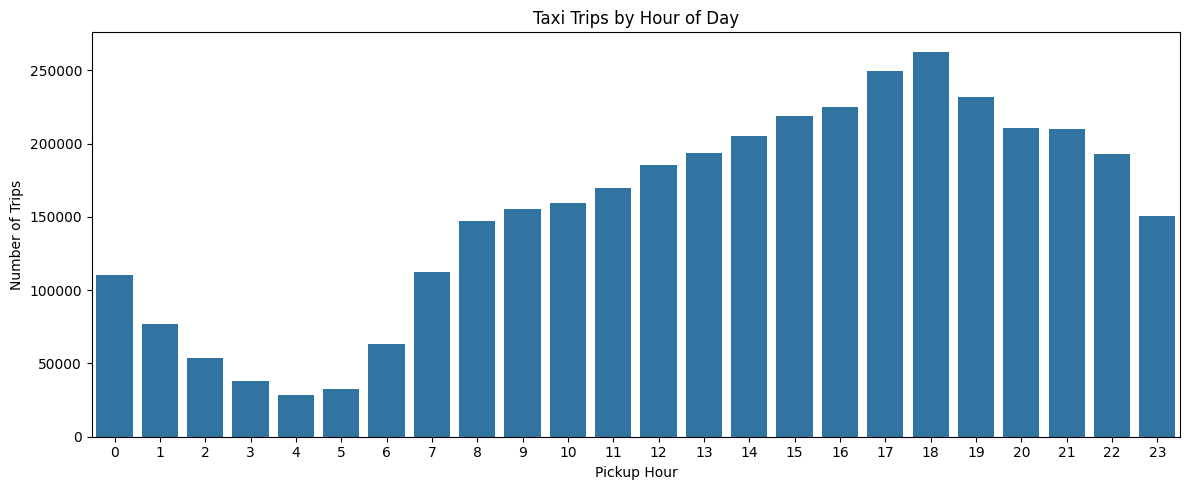

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

if "pickup_hour" in clean_df.columns:
    hourly_trips = (
        clean_df["pickup_hour"]
        .value_counts()
        .sort_index()
    )

    plt.figure(figsize=(12, 5))
    sns.barplot(
        x=hourly_trips.index,
        y=hourly_trips.values
    )
    plt.title("Taxi Trips by Hour of Day")
    plt.xlabel("Pickup Hour")
    plt.ylabel("Number of Trips")
    plt.tight_layout()
    plt.show()

In [9]:
# Keep only columns that actually exist
desired_columns = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "trip_distance",
    "fare_amount",
    "total_amount",
    "passenger_count",
    "PULocationID",
    "DOLocationID",
    "trip_duration_min",
    "pickup_hour",
    "pickup_day",
    "pickup_month"
]

available_columns = [
    col for col in desired_columns
    if col in clean_df.columns
]

dashboard_df = clean_df[available_columns].copy()

dashboard_df.to_csv(
    "taxi_dashboard_data.csv",
    index=False
)

print("Exported rows:", len(dashboard_df))
print("Exported columns:", dashboard_df.columns.tolist())

files.download("taxi_dashboard_data.csv")

Exported rows: 3684004
Exported columns: ['tpep_pickup_datetime', 'tpep_dropoff_datetime', 'trip_distance', 'fare_amount', 'total_amount', 'passenger_count', 'PULocationID', 'DOLocationID', 'trip_duration_min', 'pickup_hour', 'pickup_day', 'pickup_month']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>